,month,orders,order_value_usd
0,2026-01,8,1185.91
1,2026-02,7,1439.91
2,2026-03,6,1220.90
3,2026-04,6,1073.94
4,2026-05,6,1045.92
5,2026-06,4,324.95
6,2026-07,8,895.90
7,2026-08,5,605.94


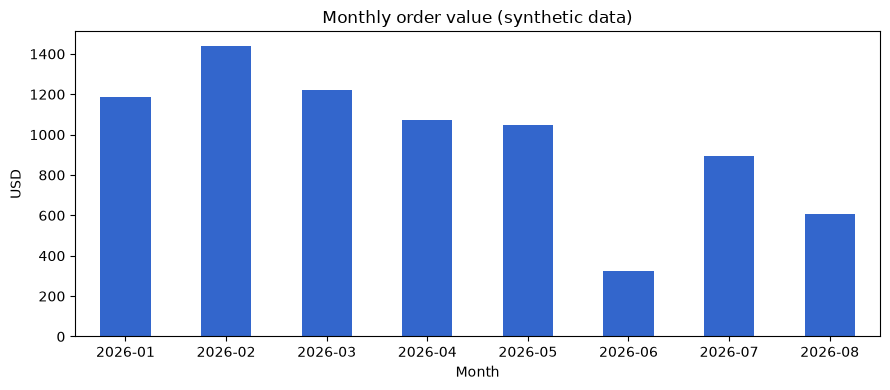

In [1]:
from pathlib import Path
import sqlite3

import matplotlib.pyplot as plt
import pandas as pd

db_path = Path("../data/shop.db")
assert db_path.exists(), f"Database not found: {db_path.resolve()}"

with sqlite3.connect(db_path) as conn:
    monthly = pd.read_sql_query(
        """
        SELECT strftime('%Y-%m', order_date) AS month,
               COUNT(*) AS orders,
               ROUND(SUM(total_cents) / 100.0, 2) AS order_value_usd
        FROM orders
        GROUP BY strftime('%Y-%m', order_date)
        ORDER BY month
        """,
        conn,
    )

display(monthly)

ax = monthly.plot(
    x="month",
    y="order_value_usd",
    kind="bar",
    legend=False,
    figsize=(9, 4),
    color="#3366cc",
)
ax.set(
    title="Monthly order value (synthetic data)",
    xlabel="Month",
    ylabel="USD",
)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

,product,orders,revenue_usd
0,Mechanical Keyboard,18,4142.00
1,Wireless Headphones,10,1759.78
2,USB-C Dock,5,714.89
3,Laptop Stand,11,626.81
4,Webcam,6,549.89


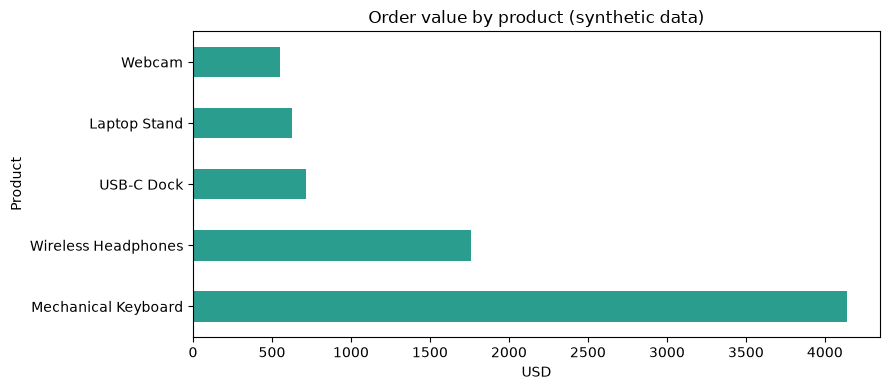

In [2]:
with sqlite3.connect(db_path) as conn:
    product_revenue = pd.read_sql_query(
        """
        SELECT p.name AS product,
               COUNT(o.order_id) AS orders,
               ROUND(SUM(o.total_cents) / 100.0, 2) AS revenue_usd
        FROM orders AS o
        JOIN products AS p ON p.product_id = o.product_id
        GROUP BY p.product_id, p.name
        ORDER BY revenue_usd DESC
        """,
        conn,
    )

display(product_revenue)

ax = product_revenue.plot(
    x="product",
    y="revenue_usd",
    kind="barh",
    legend=False,
    figsize=(9, 4),
    color="#2a9d8f",
)
ax.set(
    title="Order value by product (synthetic data)",
    xlabel="USD",
    ylabel="Product",
)
plt.tight_layout()
plt.show()

,rating,review_count
0,1,8
1,2,2
2,3,4
3,4,8
4,5,8


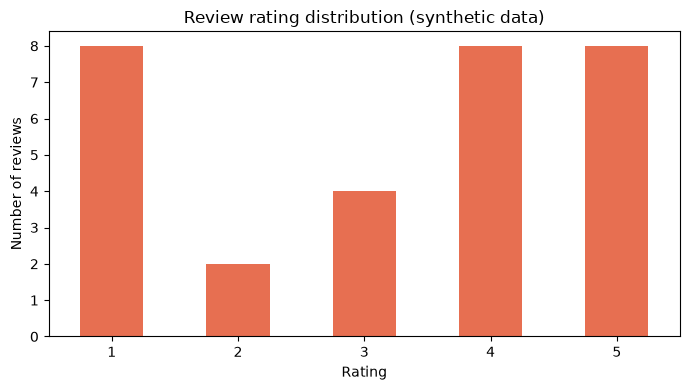

In [3]:
import os

from dotenv import load_dotenv
from pymongo import MongoClient

load_dotenv("../.env")

uri = os.getenv("MONGODB_URI")
assert uri, "MONGODB_URI was not found in ../.env"

client = MongoClient(uri, serverSelectionTimeoutMS=10000)

try:
    review_rows = list(
        client["ecommerce_support"]["reviews"].aggregate([
            {
                "$group": {
                    "_id": "$rating",
                    "review_count": {"$sum": 1},
                }
            },
            {"$sort": {"_id": 1}},
        ])
    )
finally:
    client.close()

ratings = pd.DataFrame(review_rows).rename(columns={"_id": "rating"})
display(ratings)

ax = ratings.plot(
    x="rating",
    y="review_count",
    kind="bar",
    legend=False,
    figsize=(7, 4),
    color="#e76f51",
)
ax.set(
    title="Review rating distribution (synthetic data)",
    xlabel="Rating",
    ylabel="Number of reviews",
)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()